In [6]:
import torch
import torch.nn as nn
import torch.utils.data as data

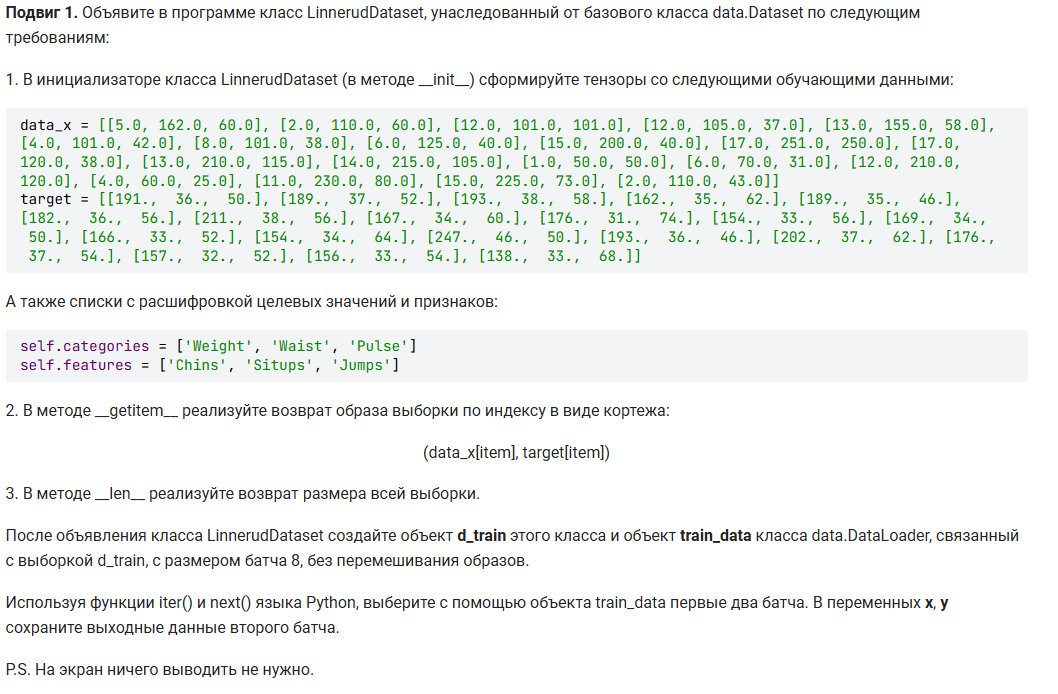

In [22]:
class LinnerudDataset(data.Dataset):
    def __init__(self):
        data_x = [[5.0, 162.0, 60.0], [2.0, 110.0, 60.0], [12.0, 101.0, 101.0], [12.0, 105.0, 37.0], [13.0, 155.0, 58.0], [4.0, 101.0, 42.0], [8.0, 101.0, 38.0], [6.0, 125.0, 40.0], [15.0, 200.0, 40.0], [17.0, 251.0, 250.0], [17.0, 120.0, 38.0], [13.0, 210.0, 115.0], [14.0, 215.0, 105.0], [1.0, 50.0, 50.0], [6.0, 70.0, 31.0], [12.0, 210.0, 120.0], [4.0, 60.0, 25.0], [11.0, 230.0, 80.0], [15.0, 225.0, 73.0], [2.0, 110.0, 43.0]]
        target = [[191.,  36.,  50.], [189.,  37.,  52.], [193.,  38.,  58.], [162.,  35.,  62.], [189.,  35.,  46.], [182.,  36.,  56.], [211.,  38.,  56.], [167.,  34.,  60.], [176.,  31.,  74.], [154.,  33.,  56.], [169.,  34.,  50.], [166.,  33.,  52.], [154.,  34.,  64.], [247.,  46.,  50.], [193.,  36.,  46.], [202.,  37.,  62.], [176.,  37.,  54.], [157.,  32.,  52.], [156.,  33.,  54.], [138.,  33.,  68.]]

        self.data_x = torch.tensor(data_x)
        self.target = torch.tensor(target)
        
        self.categories = ['Weight', 'Waist', 'Pulse']
        self.features = ['Chins', 'Situps', 'Jumps']


    def __getitem__(self, item):
        return (self.data_x[item], self.target[item])


    def __len__(self):
        return len(self.data_x)


d_train = LinnerudDataset()
train_data = data.DataLoader(d_train, batch_size=, shuffle=False)

it = iter(train_data)
next(it)

x, y = next(it)




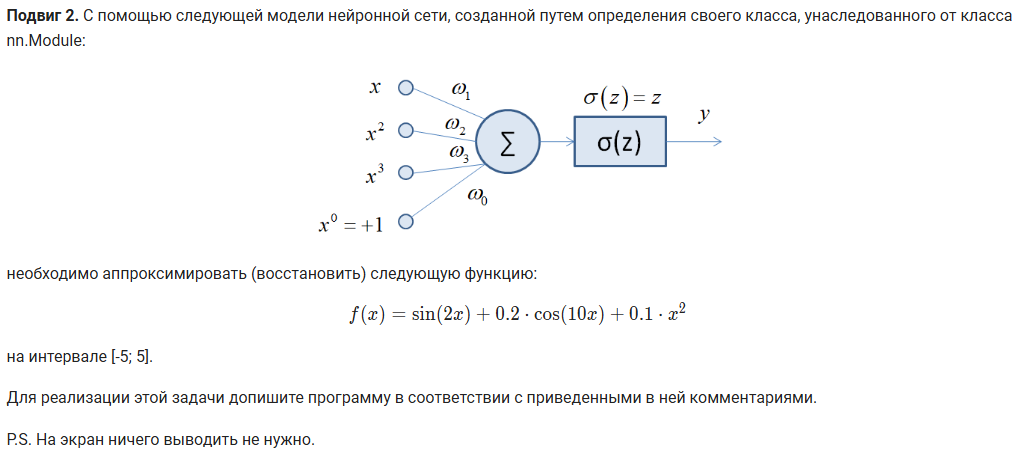

In [7]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

def func(x):
    return torch.sin(2*x) + 0.2*torch.cos(10*x) + 0.1*x*x
    

class FuncDataset(data.Dataset):
    def __init__(self):
        _x = torch.arange(-5, 5, 0.1)
        self.data = _x
        self.target = func(_x) # значения функции в точках _x
        self.length = len(_x) # размер обучающей выборки

    def __getitem__(self, item):
        # возврат образа по индексу item в виде кортежа: (данные, целевое значение)
        return (self.data[item], self.target[item])

    def __len__(self):
        # возврат размера выборки
        return self.length


class FuncModel(nn.Module):
    def __init__(self):
        super().__init__()
        # модель однослойной полносвязной нейронной сети:
        # 1-й слой: число входов 3 (x, x^2, x^3), число нейронов 1
        self.layer1 = nn.Linear(3, 1, bias=True)

    def forward(self, x):
        xx = torch.empty(x.size(0), 3)
        xx[:, 0] = x
        xx[:, 1] = x ** 2
        xx[:, 2] = x ** 3
        y = self.layer1(xx)
        return y


torch.manual_seed(1)

# создать модель FuncModel
# перевести модель в режим обучения
model = FuncModel()
model.train()


epochs = 20 # число эпох обучения
batch_size = 8 # размер батча

# создать объект класса FuncDataset
d_train = FuncDataset() 

# создать объект класса DataLoader с размером пакетов batch_size и перемешиванием образов выборки
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True) 

optimizer = optim.Adam(model.parameters(), lr=0.01) # создать оптимизатор Adam для обучения модели с шагом обучения 0.01
loss_func = nn.MSELoss() # создать функцию потерь с помощью класса MSELoss

for _e in range(epochs): # итерации по эпохам
    for x_train, y_train in train_data:
        predict = model(x_train) # вычислить прогноз модели для данных x_train
        loss = loss_func(predict.squeeze(), y_train) # вычислить значение функции потерь
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# перевести модель в режим эксплуатации
model.eval()

# выполнить прогноз модели по всем данным выборки (d_train.data)
pred = model(d_train.data)

Q = loss_func(pred.squeeze(), d_train.target).item() # вычислить потери с помощью loss_func по всем данным выборки; значение Q сохранить в виде вещественного числа

In [8]:
Q

0.9019888043403625

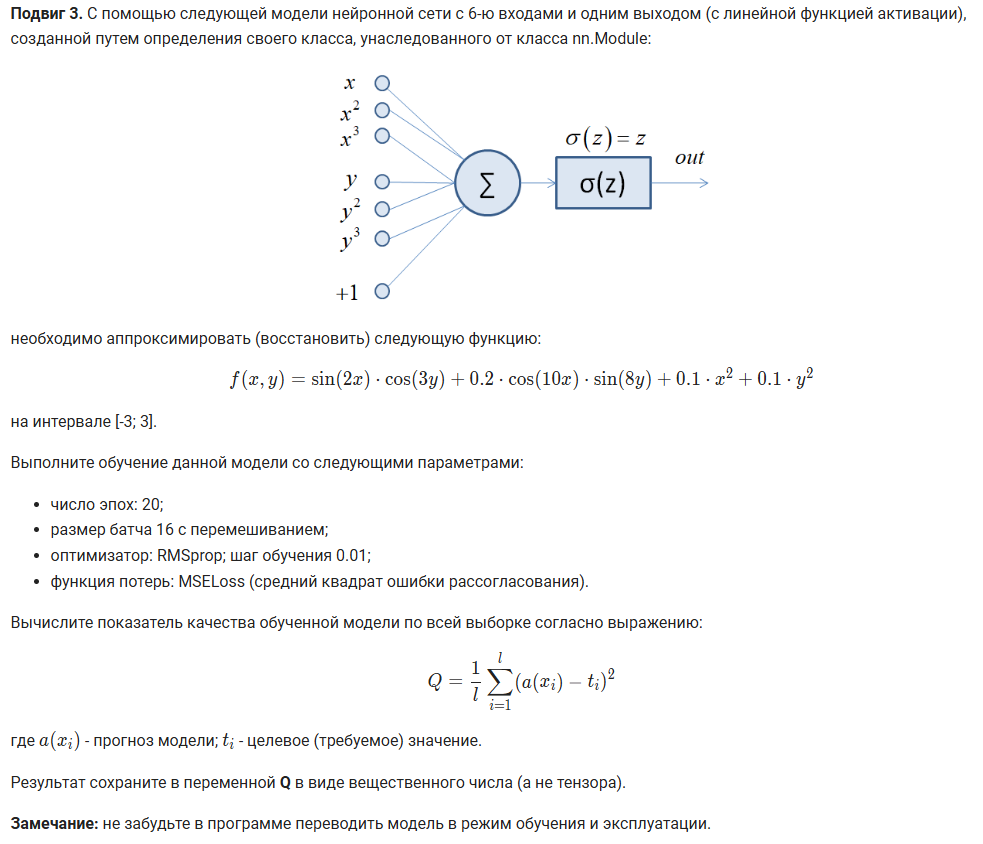

In [3]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim
    
class FuncDataset(data.Dataset):
    def __init__(self):
        _range = torch.arange(-3, 3, 0.1)
        self.data = torch.tensor([(_x, _y) for _x in _range for _y in _range])
        self.target = self._func(self.data)
        self.length = self.data.shape[0] # размер обучающей выборки

    @staticmethod
    def _func(coord):
        _x, _y = coord[:, 0], coord[:, 1]
        return torch.sin(2 * _x) * torch.cos(3 * _y) + 0.2 * torch.cos(10 * _x) * torch.sin(8 * _x) + 0.1 * _x ** 2 + 0.1 * _y ** 2

    def __getitem__(self, item):
        # возврат образа по индексу item в виде кортежа: (данные, целевое значение)
        return (self.data[item], self.target[item])

    def __len__(self):
        # возврат размера выборки
        return self.length


class FuncModel(nn.Module):
    def __init__(self):
        super().__init__()
        # модель однослойной полносвязной нейронной сети:
        # 1-й слой: число входов 6 (x, x^2, x^3, y, y^2, y^3), число нейронов 1
        self.layer1 = nn.Linear(6, 1)

    def forward(self, coord):
        x, y = coord[:, 0], coord[:, 1]
        x.unsqueeze_(-1)
        y.unsqueeze_(-1)

        xx = torch.empty(coord.size(0), 6)
        xx[:, :3] = torch.cat([x, x ** 2, x ** 3], dim=1)
        xx[:, 3:] = torch.cat([y, y ** 2, y ** 3], dim=1)
        y = self.layer1(xx)
        return y

# здесь продолжайте программу
torch.manual_seed(1)

# создать модель FuncModel
# перевести модель в режим обучения
model = FuncModel()
model.train()


epochs = 20 # число эпох обучения
batch_size = 16 # размер батча

# создать объект класса FuncDataset
d_train = FuncDataset() 

# создать объект класса DataLoader с размером пакетов batch_size и перемешиванием образов выборки
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True) 

optimizer = optim.RMSprop(model.parameters(), lr=0.01) # создать оптимизатор Adam для обучения модели с шагом обучения 0.01
loss_func = nn.MSELoss() # создать функцию потерь с помощью класса MSELoss

for _e in range(epochs): # итерации по эпохам
    for x_train, y_train in train_data:
        predict = model(x_train) # вычислить прогноз модели для данных x_train
        loss = loss_func(predict.squeeze(), y_train) # вычислить значение функции потерь
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# перевести модель в режим эксплуатации
model.eval()

# выполнить прогноз модели по всем данным выборки (d_train.data)
pred = model(d_train.data)

Q = loss_func(pred.squeeze(), d_train.target).item() # вычислить потери с помощью loss_func по всем данным выборки; значение Q сохранить в виде вещественного числа

In [4]:
Q

0.28094252943992615

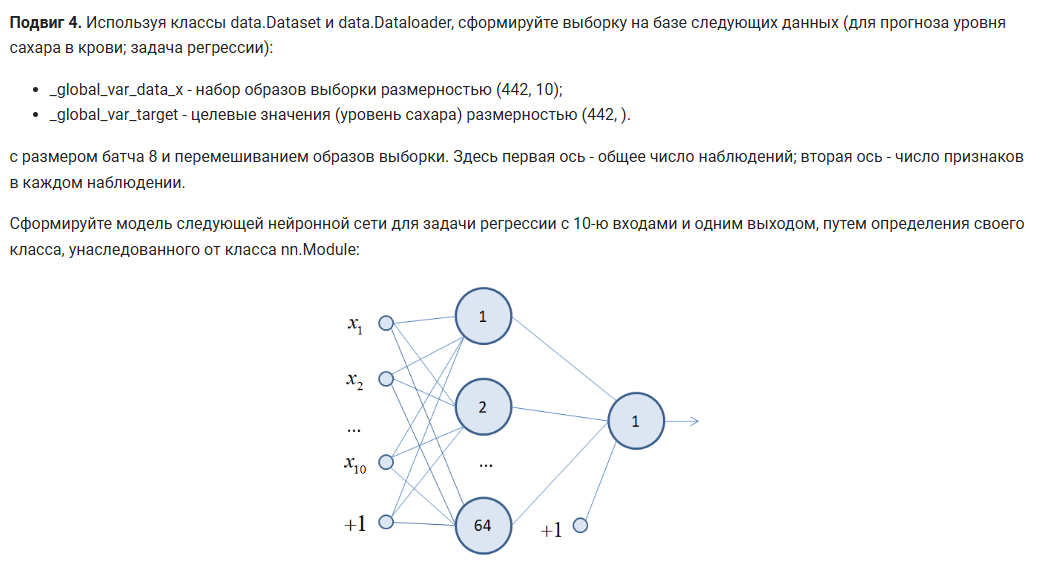

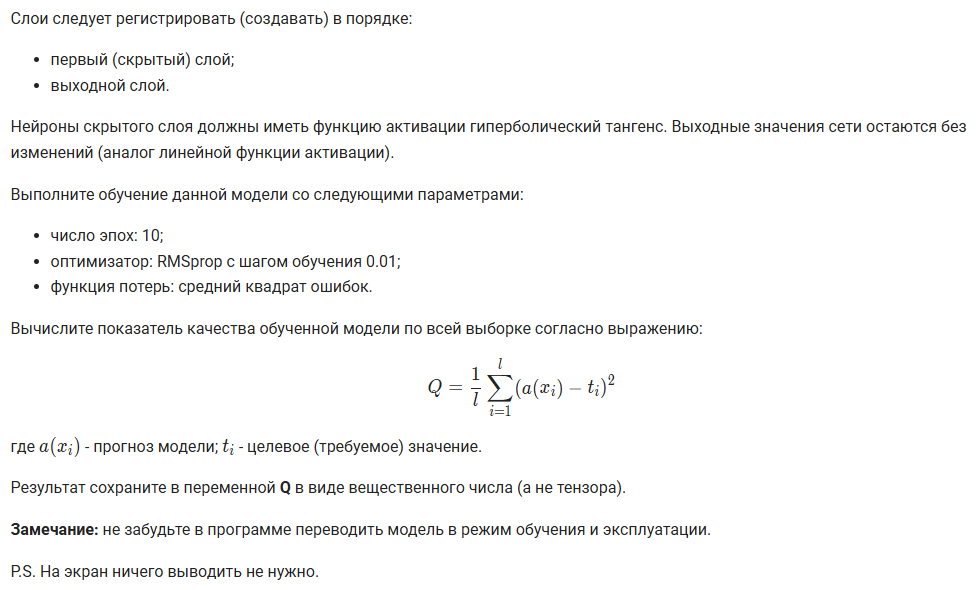

In [32]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

_global_var_data_x = torch.normal(mean=0, std=1, size=(442, 10))
_global_var_target = torch.normal(mean=0, std=1, size=(442, 1))

# здесь продолжайте программу
class FuncDataset(data.Dataset):
    def __init__(self):
        self.length = len(_global_var_data_x)
        self.data = _global_var_data_x.clone().detach()
        self.target = _global_var_target.clone().detach()

    def __getitem__(self, item):
        return (self.data[item], self.target[item])

    def __len__(self):
        return self.length


class FuncModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(10, 64, bias=True)
        self.layer2 = nn.Linear(64, 1, bias=True)
        self.act = nn.Tanh()

    def forward(self, coord):
        x = self.layer1(coord)
        x = self.act(x)
        y = self.layer2(x)
        return y


# здесь продолжайте программу
torch.manual_seed(1)

# создать модель FuncModel
# перевести модель в режим обучения
model = FuncModel()
model.train()

epochs = 10 # число эпох обучения
batch_size = 8 # размер батча

# создать объект класса FuncDataset
d_train = FuncDataset() 

# создать объект класса DataLoader с размером пакетов batch_size и перемешиванием образов выборки
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True) 

optimizer = optim.RMSprop(model.parameters(), lr=0.01) # создать оптимизатор Adam для обучения модели с шагом обучения 0.01
loss_func = nn.MSELoss() # создать функцию потерь с помощью класса MSELoss 


for _e in range(epochs): # итерации по эпохам
    for x_train, y_train in train_data:
        predict = model(x_train) # вычислить прогноз модели для данных x_train
        loss = loss_func(predict.squeeze(), y_train) # вычислить значение функции потерь
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# перевести модель в режим эксплуатации
model.eval()

# выполнить прогноз модели по всем данным выборки (d_train.data)
pred = model(d_train.data)

Q = loss_func(pred.squeeze(), d_train.target).item() # вычислить потери с помощью loss_func по всем данным выборки; значение Q сохранить в виде вещественного числа




In [33]:
Q

1.1208564043045044

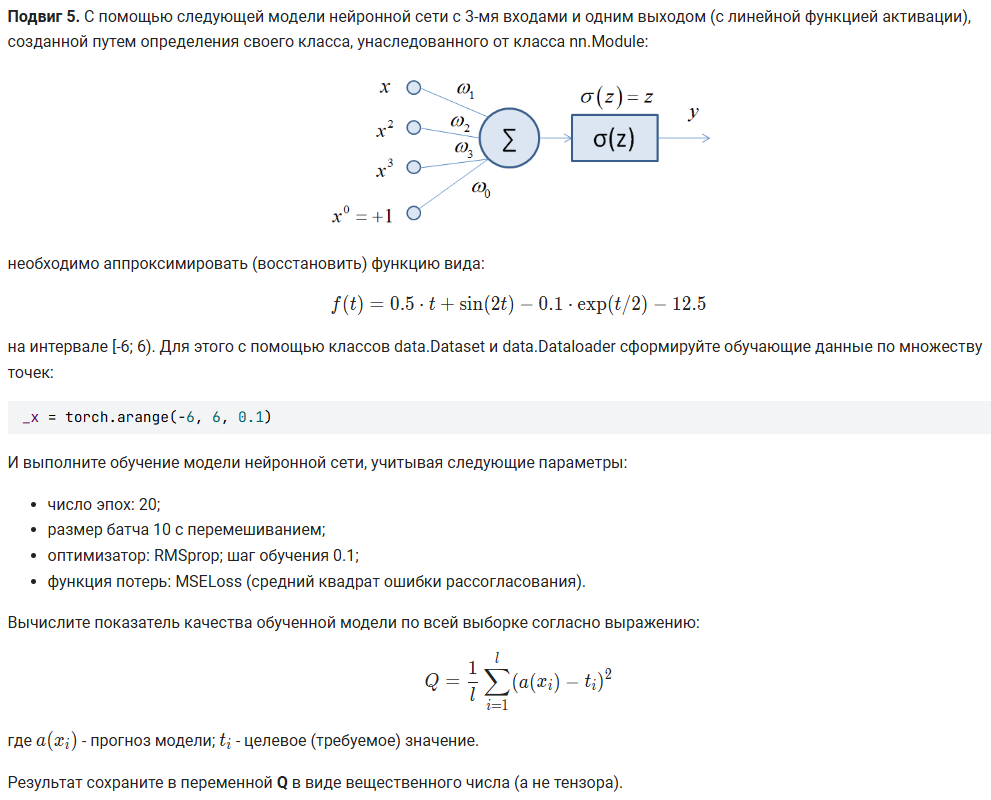

In [50]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim


# здесь продолжайте программу
class FuncDataset(data.Dataset):
    def __init__(self):
        _x = torch.arange(-6, 6, 0.1)
        self.length = len(_x)
        self.data = _x
        self.target = self._func(self.data)

    @staticmethod
    def _func(t):
        return 0.5*t+torch.sin(2*t) - 0.1*torch.exp(t/2) - 12.5
    
    def __getitem__(self, item):
        return (self.data[item], self.target[item])

    def __len__(self):
        return self.length


class FuncModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(3, 1, bias=True)

    def forward(self, x):
        x.unsqueeze_(dim=1)
        x = torch.cat([x, x ** 2, x ** 3], dim=1)
        y = self.layer1(x)
        return y


# здесь продолжайте программу
torch.manual_seed(1)

# создать модель FuncModel
# перевести модель в режим обучения
model = FuncModel()
model.train()

epochs = 20 # число эпох обучения
batch_size = 10 # размер батча

# создать объект класса FuncDataset
d_train = FuncDataset() 

# создать объект класса DataLoader с размером пакетов batch_size и перемешиванием образов выборки
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True) 

optimizer = optim.RMSprop(model.parameters(), lr=0.1) # создать оптимизатор Adam для обучения модели с шагом обучения 0.01
loss_func = nn.MSELoss() # создать функцию потерь с помощью класса MSELoss 

for _e in range(epochs): # итерации по эпохам
    for x_train, y_train in train_data:
        # print(x_train.shape)
        predict = model(x_train) # вычислить прогноз модели для данных x_train
        loss = loss_func(predict.squeeze(), y_train) # вычислить значение функции потерь
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# перевести модель в режим эксплуатации
model.eval()

# выполнить прогноз модели по всем данным выборки (d_train.data)
pred = model(d_train.data)

Q = loss_func(pred.squeeze(), d_train.target).item() # вычислить потери с помощью loss_func по всем данным выборки; значение Q сохранить в виде вещественного числа

In [51]:
Q

1.3062682151794434